In [ ]:
import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)  # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(1)
hidden = 4
W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))

h = sigmoid(X @ W1 + b1)  # hidden activations, 4 x hidden
o = sigmoid(h @ W2 + b2)  # output, 4 x 1
print('initial loss:', float(np.mean((o - y)**2)))

initial loss: 0.2748629616482994


In [ ]:
def train_xor(lr, epochs=20000, seed=1, hidden=4):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
    loss = []
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1)  # forward
        o = sigmoid(h @ W2 + b2)
        loss.append(float(np.mean((o - y)**2)))

        do = (o - y) * o * (1 - o)  # backward
        dW2 = h.T @ do; db2 = do.sum(0, keepdims=True)
        dh = (do @ W2.T) * h * (1 - h)
        dW1 = X.T @ dh; db1 = dh.sum(0, keepdims=True)

        W2 -= lr*dW2; b2 -= lr*db2  # gradient descent
        W1 -= lr*dW1; b1 -= lr*db1

    return (W1, b1, W2, b2), np.array(loss)

params, loss = train_xor(2.0)
W1, b1, W2, b2 = params
print('final loss:', loss[-1])
print('predictions:', sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2).ravel().round(3))

final loss: 2.4552864803967283e-05
predictions: [0.004 0.995 0.996 0.006]


lr=0.05: final MSE = 2.31e-03
lr=0.5: final MSE = 1.11e-04
lr=2.0: final MSE = 2.46e-05


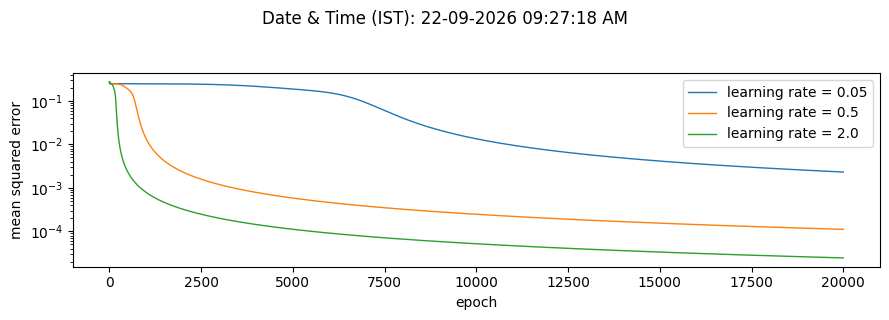

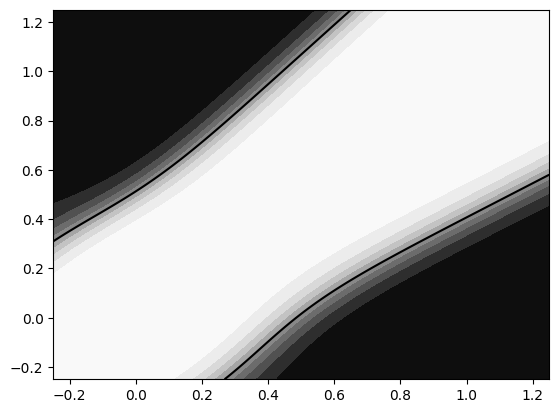

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))
#Add this code after figsize
from datetime import datetime
from zoneinfo import ZoneInfo

ist_now = datetime.now(ZoneInfo("Asia/Kolkata"))
plt.suptitle(
    f"Date & Time (IST): {ist_now.strftime('%d-%m-%Y %I:%M:%S %p')}",
    y=1.05
)
for lr in (0.05, 0.5, 2.0):
    _, l = train_xor(lr)
    plt.semilogy(l, lw=1.0, label=f'learning rate = {lr}')
    print(f'lr={lr}: final MSE = {l[-1]:.2e}')
plt.xlabel('epoch'); plt.ylabel('mean squared error'); plt.legend()
plt.tight_layout(); plt.show()

gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300),
                     np.linspace(-0.25, 1.25, 300))
G = np.c_[gx.ravel(), gy.ravel()]
Z = sigmoid(sigmoid(G @ W1 + b1) @ W2 + b2).reshape(gx.shape)
plt.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap='Greys')
plt.contour(gx, gy, Z, levels=[0.5], colors='k')
plt.show()